# Problem 1: Naive Bayes Classifier

Accuracy: 0.9264214046822743

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.93      0.93       149
           1       0.93      0.92      0.93       150

    accuracy                           0.93       299
   macro avg       0.93      0.93      0.93       299
weighted avg       0.93      0.93      0.93       299

Confusion Matrix:
 [[139  10]
 [ 12 138]]


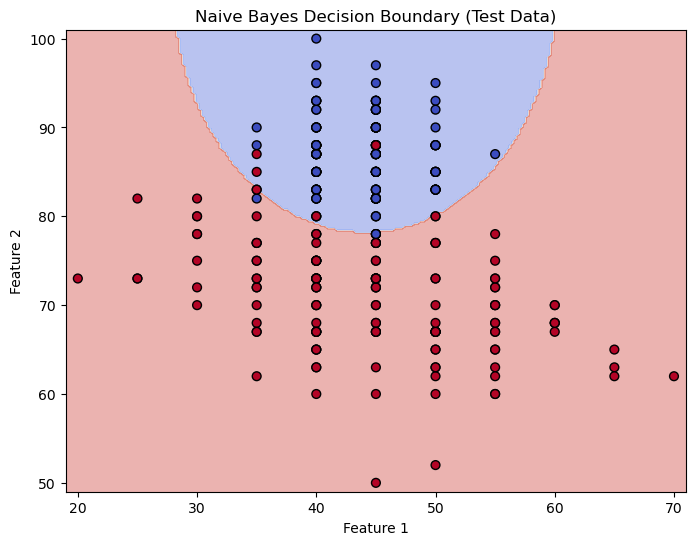

In [2]:
# ======================= Naive Bayes Classifier (From Scratch) =======================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ---------- Step 1: Load Dataset ----------
df = pd.read_csv("Naive-Bayes-Classification-Data.csv")
X = df.iloc[:, :-1].values    # Features
y = df.iloc[:, -1].values     # Target

# ---------- Step 2: Train-Test Split ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# ---------- Step 3: Implement Gaussian Naive Bayes ----------
class GaussianNaiveBayes:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.parameters = {}
        for c in self.classes:
            X_c = X[y == c]
            self.parameters[c] = {
                "mean": X_c.mean(axis=0),
                "var": X_c.var(axis=0),
                "prior": X_c.shape[0] / X.shape[0],
            }

    def gaussian_pdf(self, class_idx, x):
        mean = self.parameters[class_idx]["mean"]
        var = self.parameters[class_idx]["var"]
        numerator = np.exp(-((x - mean) ** 2) / (2 * var))
        denominator = np.sqrt(2 * np.pi * var)
        return numerator / denominator

    def predict(self, X):
        y_pred = []
        for x in X:
            posteriors = []
            for c in self.classes:
                prior = np.log(self.parameters[c]["prior"])
                conditional = np.sum(np.log(self.gaussian_pdf(c, x)))
                posterior = prior + conditional
                posteriors.append(posterior)
            y_pred.append(self.classes[np.argmax(posteriors)])
        return np.array(y_pred)

# ---------- Step 4: Train Model ----------
nb = GaussianNaiveBayes()
nb.fit(X_train, y_train)

# ---------- Step 5: Predict ----------
y_pred = nb.predict(X_test)

# ---------- Step 6: Evaluate ----------
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# ---------- Step 7: Visualization ----------
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

Z = nb.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.4, cmap='coolwarm')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, s=40, edgecolor='k', cmap='coolwarm')
plt.title("Naive Bayes Decision Boundary (Test Data)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()



# Problem 2: ID3 Decision Tree

In [16]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from pprint import pprint

# ---------------------------
# 1. Load Dataset
# ---------------------------
df = pd.read_csv("car_evaluation.csv")
df.columns = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']

# ---------------------------
# 2. Train-Test Split
# ---------------------------
train_data, test_data = train_test_split(df, test_size=0.3, random_state=42)

# ---------------------------
# 3. Helper Functions for ID3
# ---------------------------

def entropy(target_col):
    """Calculate entropy of a target column"""
    elements, counts = np.unique(target_col, return_counts=True)
    entropy_val = 0
    for i in range(len(elements)):
        prob = counts[i] / np.sum(counts)
        entropy_val += -prob * np.log2(prob)
    return entropy_val


def info_gain(data, split_attribute, target_name="class"):
    """Calculate Information Gain of a feature"""
    total_entropy = entropy(data[target_name])
    vals, counts = np.unique(data[split_attribute], return_counts=True)

    weighted_entropy = np.sum(
        [(counts[i] / np.sum(counts)) * entropy(data[data[split_attribute] == vals[i]][target_name])
         for i in range(len(vals))]
    )
    return total_entropy - weighted_entropy


# ---------------------------
# 4. ID3 Algorithm (Recursive Tree Builder)
# ---------------------------

def id3(data, original_data, features, target_attribute_name="class", parent_class=None, depth=0, max_depth=4):
    """Recursively build ID3 decision tree"""

    # If all target values are same — return that label
    if len(np.unique(data[target_attribute_name])) <= 1:
        return np.unique(data[target_attribute_name])[0]

    # If dataset is empty — return majority class of original dataset
    elif len(data) == 0:
        return np.unique(original_data[target_attribute_name])[
            np.argmax(np.unique(original_data[target_attribute_name], return_counts=True)[1])
        ]

    # If no features left — return majority class of current data
    elif len(features) == 0 or depth == max_depth:
        return np.unique(data[target_attribute_name])[
            np.argmax(np.unique(data[target_attribute_name], return_counts=True)[1])
        ]

    # Otherwise, choose the feature with max information gain
    else:
        parent_class = np.unique(data[target_attribute_name])[
            np.argmax(np.unique(data[target_attribute_name], return_counts=True)[1])
        ]
        gains = [info_gain(data, feature, target_attribute_name) for feature in features]
        best_feature = features[np.argmax(gains)]

        # Initialize the tree with the best feature
        tree = {best_feature: {}}

        # Remove the used feature from list
        features = [f for f in features if f != best_feature]

        # For each possible value of the best feature, build subtree
        for value in np.unique(data[best_feature]):
            sub_data = data[data[best_feature] == value]
            subtree = id3(sub_data, df, features, target_attribute_name, parent_class, depth + 1, max_depth)
            tree[best_feature][value] = subtree

        return tree


# ---------------------------
# 5. Train the Model
# ---------------------------
features = list(df.columns[:-1])
tree = id3(train_data, train_data, features)
print("\nDecision Tree (up to 4 levels):")
pprint(tree, width=120)

# ---------------------------
# 6. Prediction Function
# ---------------------------

def predict(query, tree, default="unacc"):
    """Predict the class for a single example"""
    for key in list(query.keys()):
        if key in tree.keys():
            try:
                result = tree[key][query[key]]
            except:
                return default
            if isinstance(result, dict):
                return predict(query, result)
            else:
                return result
    return default


def predict_all(test_data, tree):
    """Predict for multiple rows"""
    predictions = []
    for i in range(len(test_data)):
        query = test_data.iloc[i, :-1].to_dict()
        prediction = predict(query, tree)
        predictions.append(prediction)
    return predictions


# ---------------------------
# 7. Evaluate Accuracy
# ---------------------------
predictions = predict_all(test_data, tree)
acc = accuracy_score(test_data["class"], predictions)
print("\nAccuracy on test set:", round(acc * 100, 2), "%")


# ---------------------------
# 8. Tree Depth Function
# ---------------------------

def tree_depth(tree):
    """Find depth and breadth of the tree"""
    if not isinstance(tree, dict):
        return 0, 1  # (depth, breadth)
    else:
        depths = []
        breadths = []
        for key in tree.keys():
            for value in tree[key].values():
                d, b = tree_depth(value)
                depths.append(1 + d)
                breadths.append(b)
        return max(depths), sum(breadths)


depth, breadth = tree_depth(tree)
print("\nTree Depth:", depth)
print("Tree Breadth:", breadth)



Decision Tree (up to 4 levels):
{'safety': {'high': {'persons': {'2': 'unacc',
                                 '4': {'buying': {'high': {'maint': {'high': 'acc',
                                                                     'low': 'acc',
                                                                     'med': 'acc',
                                                                     'vhigh': 'unacc'}},
                                                  'low': {'maint': {'high': 'acc',
                                                                    'low': 'good',
                                                                    'med': 'good',
                                                                    'vhigh': 'acc'}},
                                                  'med': {'maint': {'high': 'acc',
                                                                    'low': 'vgood',
                                                                    'med': 'vgo

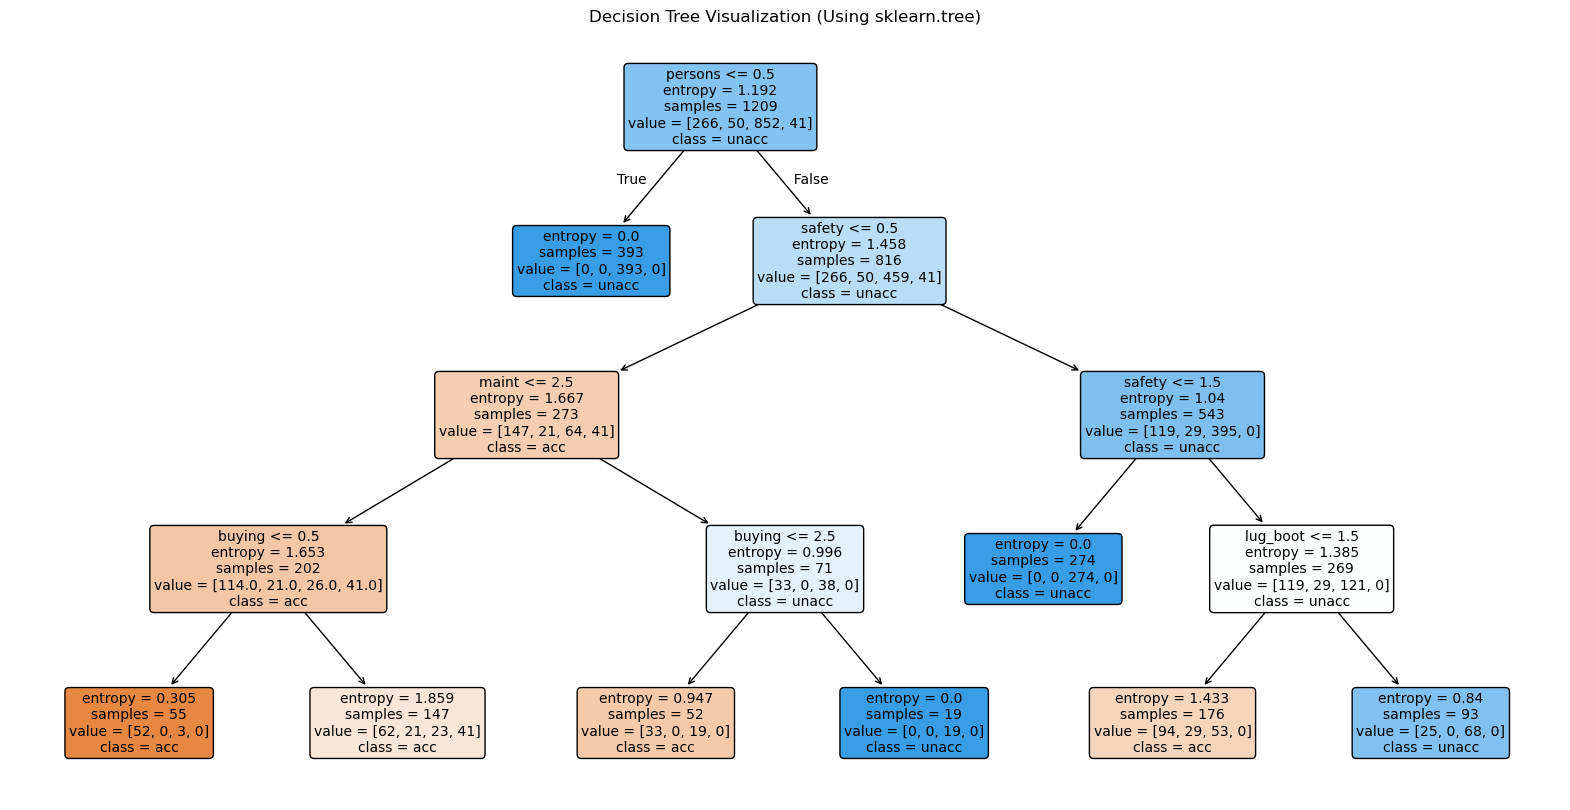

In [17]:
from sklearn import tree
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier

# ---------------------------
# Encode Categorical Variables
# ---------------------------
# sklearn's DecisionTreeClassifier requires numerical input
df_encoded = df.copy()
le_dict = {}
for column in df_encoded.columns:
    le = LabelEncoder()
    df_encoded[column] = le.fit_transform(df_encoded[column])
    le_dict[column] = le  # store encoders for reverse mapping if needed

# ---------------------------
# Train-Test Split
# ---------------------------
X = df_encoded.drop("class", axis=1)
y = df_encoded["class"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# ---------------------------
# Train sklearn Decision Tree (ID3-like)
# ---------------------------
clf = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42)
clf.fit(X_train, y_train)

# ---------------------------
# Visualization using plot_tree
# ---------------------------
plt.figure(figsize=(20, 10))
tree.plot_tree(
    clf,
    feature_names=X.columns,
    class_names=le_dict["class"].classes_,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Visualization (Using sklearn.tree)")
plt.show()
